# 02 · The Failure Lab: Where GRPO's Learning Signal Breaks, and How DAPO Responds

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samaksh97/grpo-then-and-now/blob/main/notebook/02_failure_lab.ipynb)

**GRPO, Then and Now** · core notebook · **about 40 minutes** · CPU only, runs in about 15 seconds

You will trigger GRPO's three core failure mechanisms on transparent toys (zero-gradient groups, the upper clip on rare tokens, length-dependent token weights), then switch on DAPO's response to each and measure what it costs. Optional appendices cover reward hacking, DisCO and S-GRPO, evidence at scale, and later revisions such as Dr. GRPO.

**You need:** `01_grpo_core.ipynb` (group-relative advantages and the clipped update). **Then:** `03_exercises.ipynb`, or the focused DAPO, DisCO and S-GRPO notebooks.

> Toy plots demonstrate mechanisms, not LLM-scale effects; KernelBench outcomes are illustrative (see `../data/kernelbench/README.md`).

In [1]:
# Setup: make grpo_lab importable
import sys, pathlib, subprocess
ROOT = next((p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p / "grpo_lab").exists()), None)
if ROOT is None:   # e.g. opened in Colab: fetch the repository (code, data and figures) first
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/samaksh97/grpo-then-and-now"], check=True)
    ROOT = pathlib.Path("grpo-then-and-now").resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
from grpo_lab import envs, experiments, objectives, plots

cfg = envs.Config()

## 1 · Failure mode 1: zero-gradient groups *(about 7 min)*

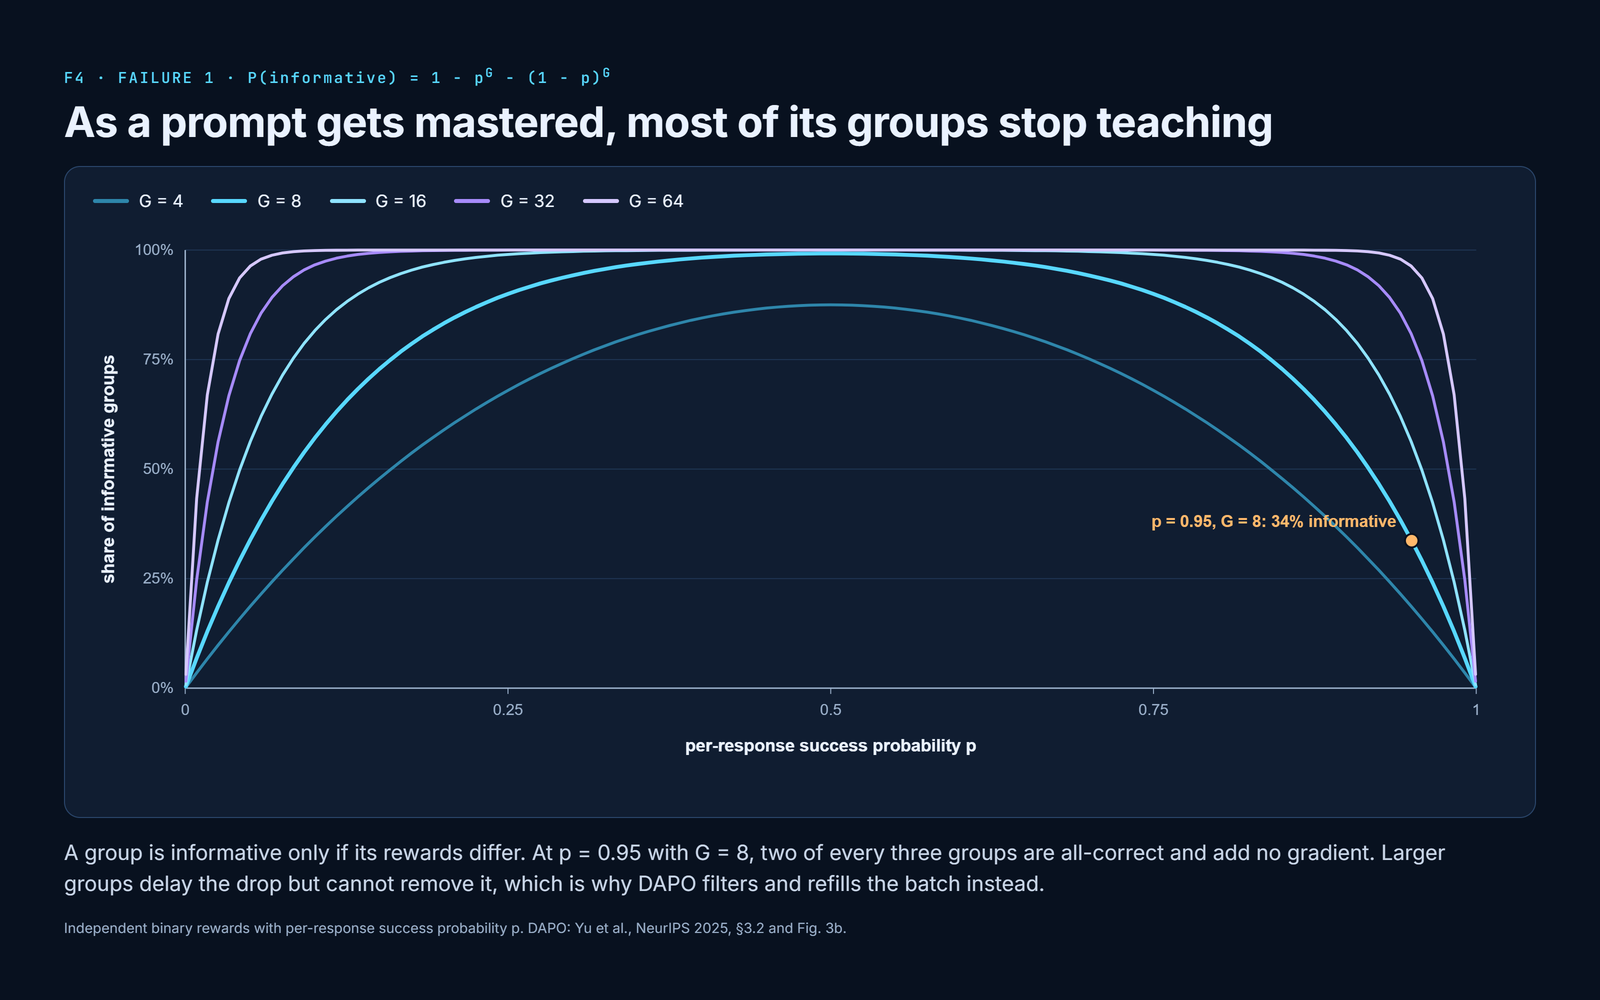

**What you'll observe:** once a prompt is nearly always solved (or never), most of its groups have identical rewards and add nothing; larger groups only delay this.

> **In plain terms:** GRPO learns by *comparing* answers to each other. If every answer in a group receives the same reward, there is nothing to compare, so that group contributes no gradient.

**The Problem:**
In GRPO, the advantage of response $i$ is:

$$
A_i = \frac{R_i - \bar{R}}{\sigma(R) + \epsilon}
$$

When all rollouts in a group achieve the same outcome (all correct: $\text{acc}=1.0$, or all failed: $\text{acc}=0.0$), the reward standard deviation is $\sigma = 0$. Consequently, the numerator $(R_i - \bar{R}) = 0$ for every sample in the group. **The advantage is exactly zero for all $G$ samples, producing zero gradient.**

**When It Happens in Practice:**
- **Early in training on hard tasks:** E.g., generating complex FlashAttention CUDA kernels where all $G=8$ samples fail compilation ($R = [0, 0, \dots, 0]$).
- **Late in training on easy tasks:** E.g., basic vector addition where all $G=8$ samples succeed ($R = [1, 1, \dots, 1]$).
- **Small group sizes ($G$):** Lower sample counts reduce the probability of drawing mixed-outcome rollouts.

**The Consequence:** At $95\%$ accuracy with $G=8$, about $66\%$ of sampled groups ($0.95^8\approx0.66$) contribute zero gradient, although their generation cost was paid.

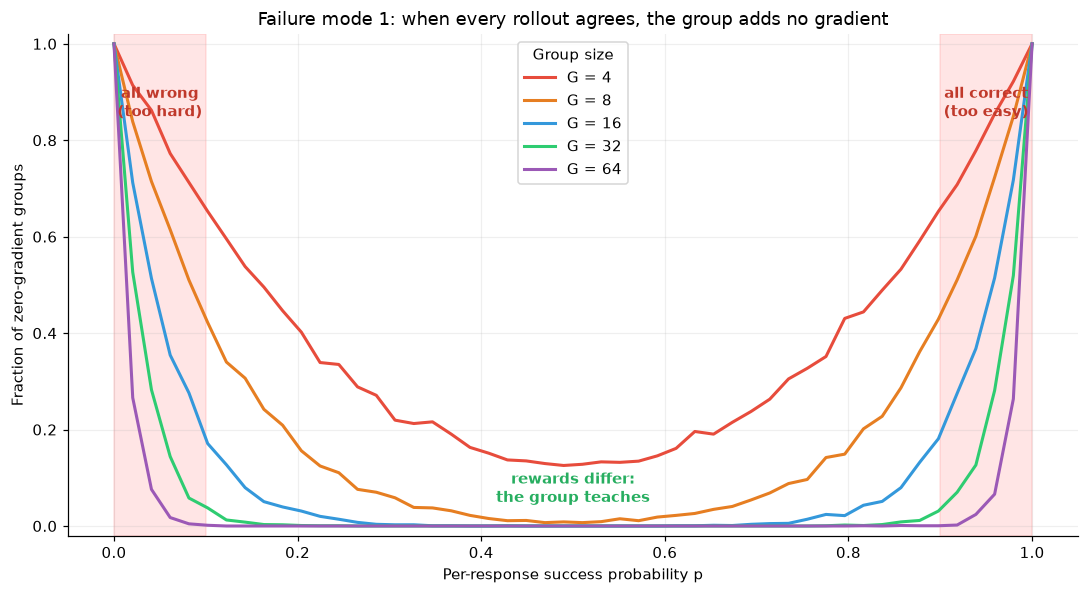

p = 0.95: 66.3% of groups at G = 8 vs 3.8% at G = 64 (8x the generation per group)
p = 0.98: 85.1% of groups at G = 8 vs 27.4% at G = 64 (8x the generation per group)


In [2]:
success_rates = np.linspace(0.0, 1.0, 50)
fractions = experiments.zero_grad_sweep(success_rates, group_sizes=[4, 8, 16, 32, 64])   # Monte Carlo, seeded
plots.zero_grad_sweep(success_rates, fractions)

# Exact share of uninformative groups for independent binary rewards: p^G + (1 - p)^G
for p in (0.95, 0.98):
    print(f"p = {p:.2f}: {objectives.zero_gradient_probability(p, 8):.1%} of groups at G = 8 vs "
          f"{objectives.zero_gradient_probability(p, 64):.1%} at G = 64 (8x the generation per group)")

In [3]:
plots.interactive_zero_grad()   # optional: sliders for p and G (needs ipywidgets)

interactive(children=(FloatSlider(value=0.95, description='p', max=1.0, step=0.01), IntSlider(value=8, descrip…

### Lesson 1 and the path forward

> **Takeaway:** GRPO gets no signal from groups without internal reward contrast. When all rollouts agree, their generation compute produces no parameter update.

**DAPO Response (Dynamic Sampling):** Filter out groups where $\text{std}(R) = 0$ during batch generation, dynamically sampling until the batch contains sufficient informative groups.

---

### Bridging to the Next Failure Mode

*Now suppose we calibrate task difficulty or enlarge group size so that our rollouts have mixed rewards. We now have non-zero advantages! But what happens at the token level when we take gradient steps on these successful rollouts?*

*This brings us to our second failure mode: **Entropy Collapse**.*

## 2 · Failure mode 2: the upper clip and exploration *(about 7 min)*

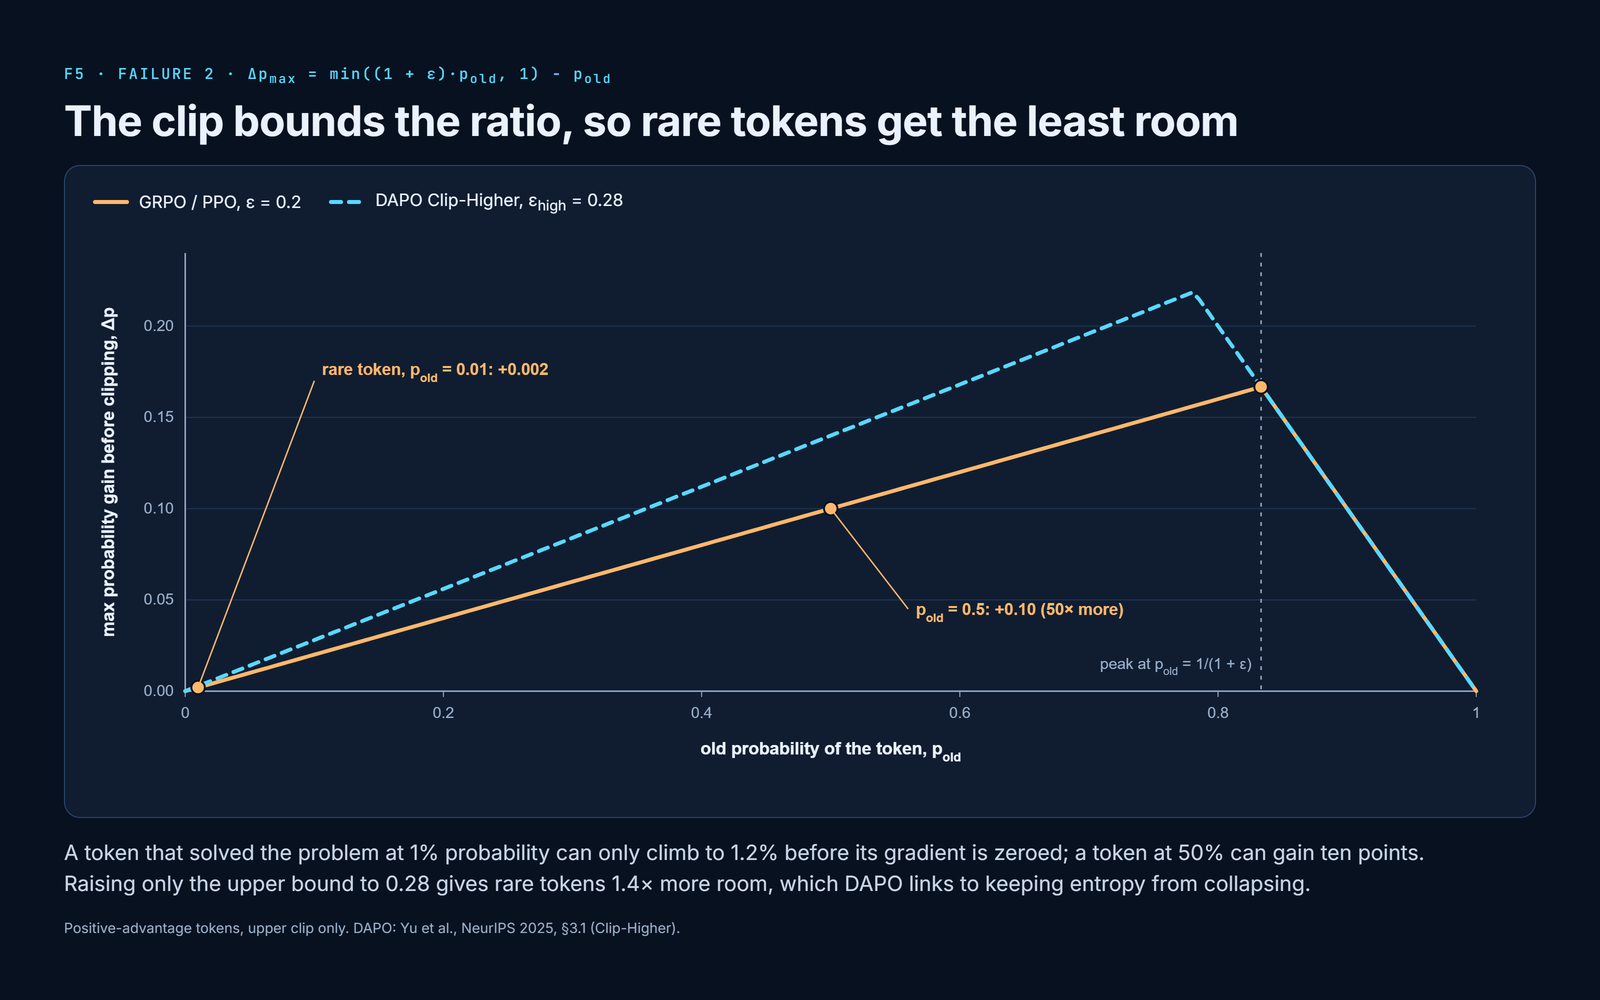

**What you'll observe:** the clip bounds the ratio, so a rare winning token can barely grow before its gradient is cut; raising only the upper bound (Clip-Higher) lets it keep climbing.

> **TL;DR:** clipping bounds the *ratio*, so a rare token can gain only about $\epsilon\,p_{\text{old}}$ in probability before its positive update is clipped. Clipping matters only after the policy has moved away from $\pi_{\text{old}}$, so the toys below take several optimizer epochs on one frozen rollout.

DAPO reports entropy collapse in large-scale GRPO training and motivates Clip-Higher. A ratio bound is relative: for a sampled token with old probability $p$, the upper cap corresponds to $p_{new}/p_{old}\le1+\epsilon_{high}$. It does not independently set normalized token probabilities, and clipping has no effect while $\pi_\theta=\pi_{old}$. The controlled experiment below therefore freezes one rollout and performs multiple optimizer epochs so measured ratios move away from one and bounds can bind. Its categorical entropy curves are pedagogical observations, not proof that a clipping choice universally causes or prevents collapse.

In [4]:
# For a sampled token with old probability p, the upper clip caps the ratio at 1 + eps_high, i.e. the
# 'nominal' probability at p * (1 + eps_high): a tiny absolute gain when p is small.
old_probabilities = np.array([0.90, 0.01])
for eps_high in [0.20, 0.28, 0.50]:
    ratio_cap = 1 + eps_high
    nominal_caps = old_probabilities * ratio_cap
    print(f'eps_high={eps_high:.2f}: ratio cap={ratio_cap:.2f}; '
          f'nominal sampled-token caps={nominal_caps}')
print('These products illustrate relative headroom only; a softmax couples all token probabilities.')

eps_high=0.20: ratio cap=1.20; nominal sampled-token caps=[1.08  0.012]
eps_high=0.28: ratio cap=1.28; nominal sampled-token caps=[1.152  0.0128]
eps_high=0.50: ratio cap=1.50; nominal sampled-token caps=[1.35  0.015]
These products illustrate relative headroom only; a softmax couples all token probabilities.


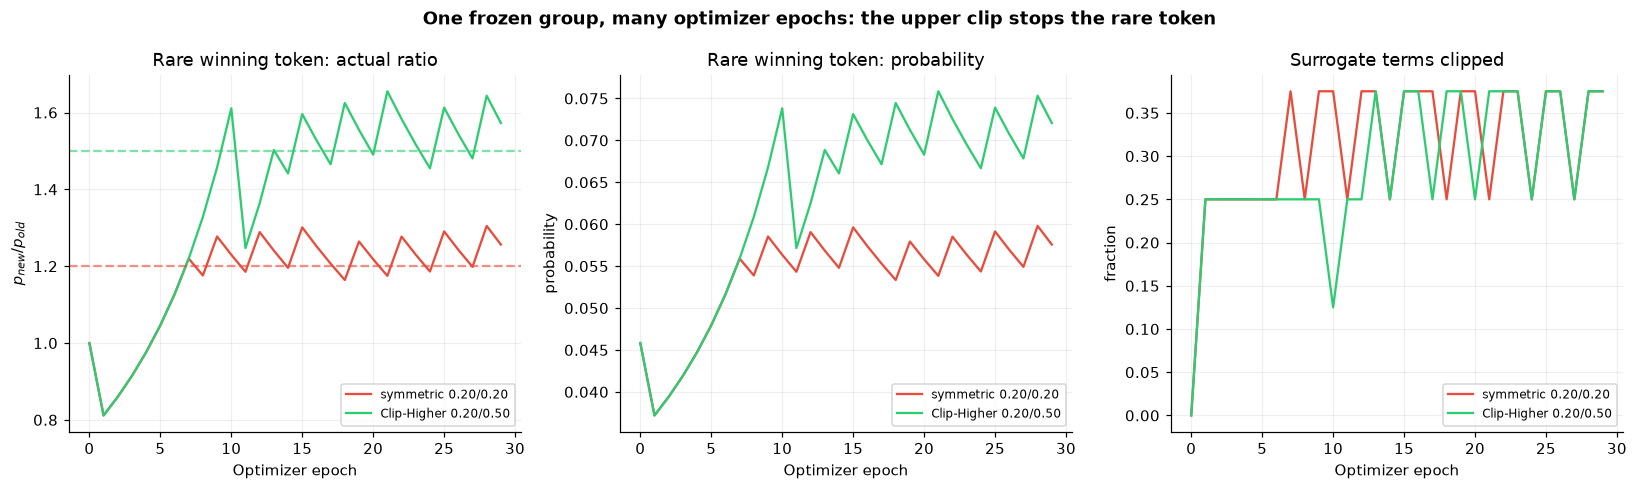

Final rare-token ratio: symmetric 1.256, Clip-Higher 1.573


In [5]:
symmetric = objectives.fixed_rollout_clip_toy(eps_low=0.20, eps_high=0.20)
clip_higher = objectives.fixed_rollout_clip_toy(eps_low=0.20, eps_high=0.50)
plots.clip_walkthrough(symmetric, clip_higher)
print(f"Final rare-token ratio: symmetric {symmetric[-1]['ratios'][5]:.3f}, "
      f"Clip-Higher {clip_higher[-1]['ratios'][5]:.3f}")

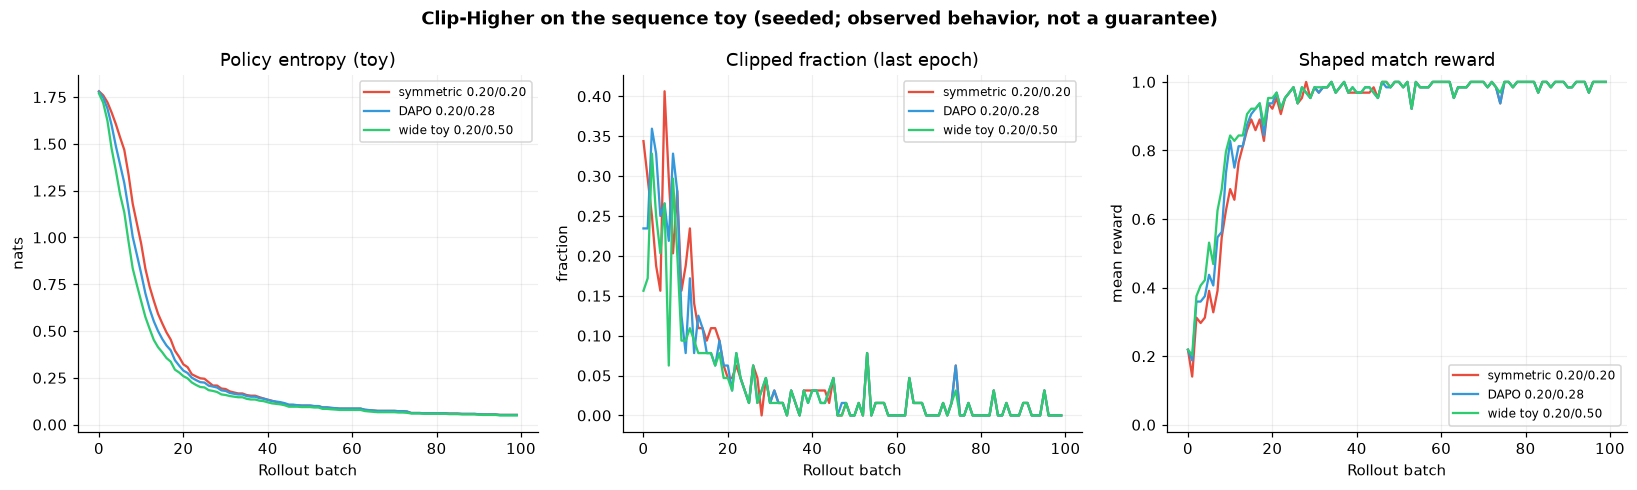

In [6]:
# The sequence toy under GRPO's symmetric clip, DAPO's 0.28 and a wide 0.5 upper bound (same seed)
settings = {"symmetric 0.20/0.20": (0.20, 0.20, plots.RED), "DAPO 0.20/0.28": (0.20, 0.28, plots.BLUE),
            "wide toy 0.20/0.50": (0.20, 0.50, plots.GREEN)}
results = {name: (experiments.train_sequence_grpo(lo, hi)[0], color) for name, (lo, hi, color) in settings.items()}
plots.clip_settings_comparison(results)

In [7]:
plots.interactive_clip_toy()   # optional: slider for eps_high (needs ipywidgets)

interactive(children=(FloatSlider(value=0.28, description='eps_high', max=0.8, min=0.1, step=0.02), Output()),…

### Lesson 2

The upper bound can stop positive-advantage surrogate terms only after the current policy has moved sufficiently far from the frozen behavior policy. Clip-Higher raises that cap. DAPO reports this as useful for preserving exploration at scale; this notebook verifies the clipping mechanism and reports toy entropy trajectories without treating them as a universal guarantee.

## 3 · Failure mode 3: length-dependent token weights *(about 6 min)*

![Per-token weight against response length on log axes for a group of 8 in which seven responses have 200 tokens: GRPO's sample-level weight falls as one over the length, so a 20-token answer weighs 10 times more per token, while DAPO's token-level weight and Dr. GRPO's constant stay nearly flat.](attachment:F06_per_token_weight_vs_length.png)

**What you'll observe:** averaging per response first gives every response the same total weight, so each token of a short response counts more; a token-level average gives every token the same weight.

> **TL;DR:** averaging within each response first gives every token of response $i$ the weight $1/(G\lvert o_i\rvert)$, so tokens of short responses count more. Token-level averaging gives every token the same weight.

Standard GRPO first averages tokens within each response and then averages responses:

$$\mathcal{L}_{\text{sample}}=-\frac{1}{G}\sum_i\frac{1}{|o_i|}\sum_t \ell_{i,t}.$$

DAPO instead normalizes once over all response tokens:

$$\mathcal{L}_{\text{token}}=-\frac{1}{\sum_i|o_i|}\sum_i\sum_t \ell_{i,t}.$$

These objectives are identical for equal-length responses. With genuinely variable lengths, sample-level averaging gives every response total weight $1/G$, so each token in a short response has a larger coefficient. Token-level normalization gives every token coefficient $1/\sum_i|o_i|$, so a response's total weight is proportional to its length. The plots below demonstrate this weighting difference only; whether it improves a task is an empirical question.
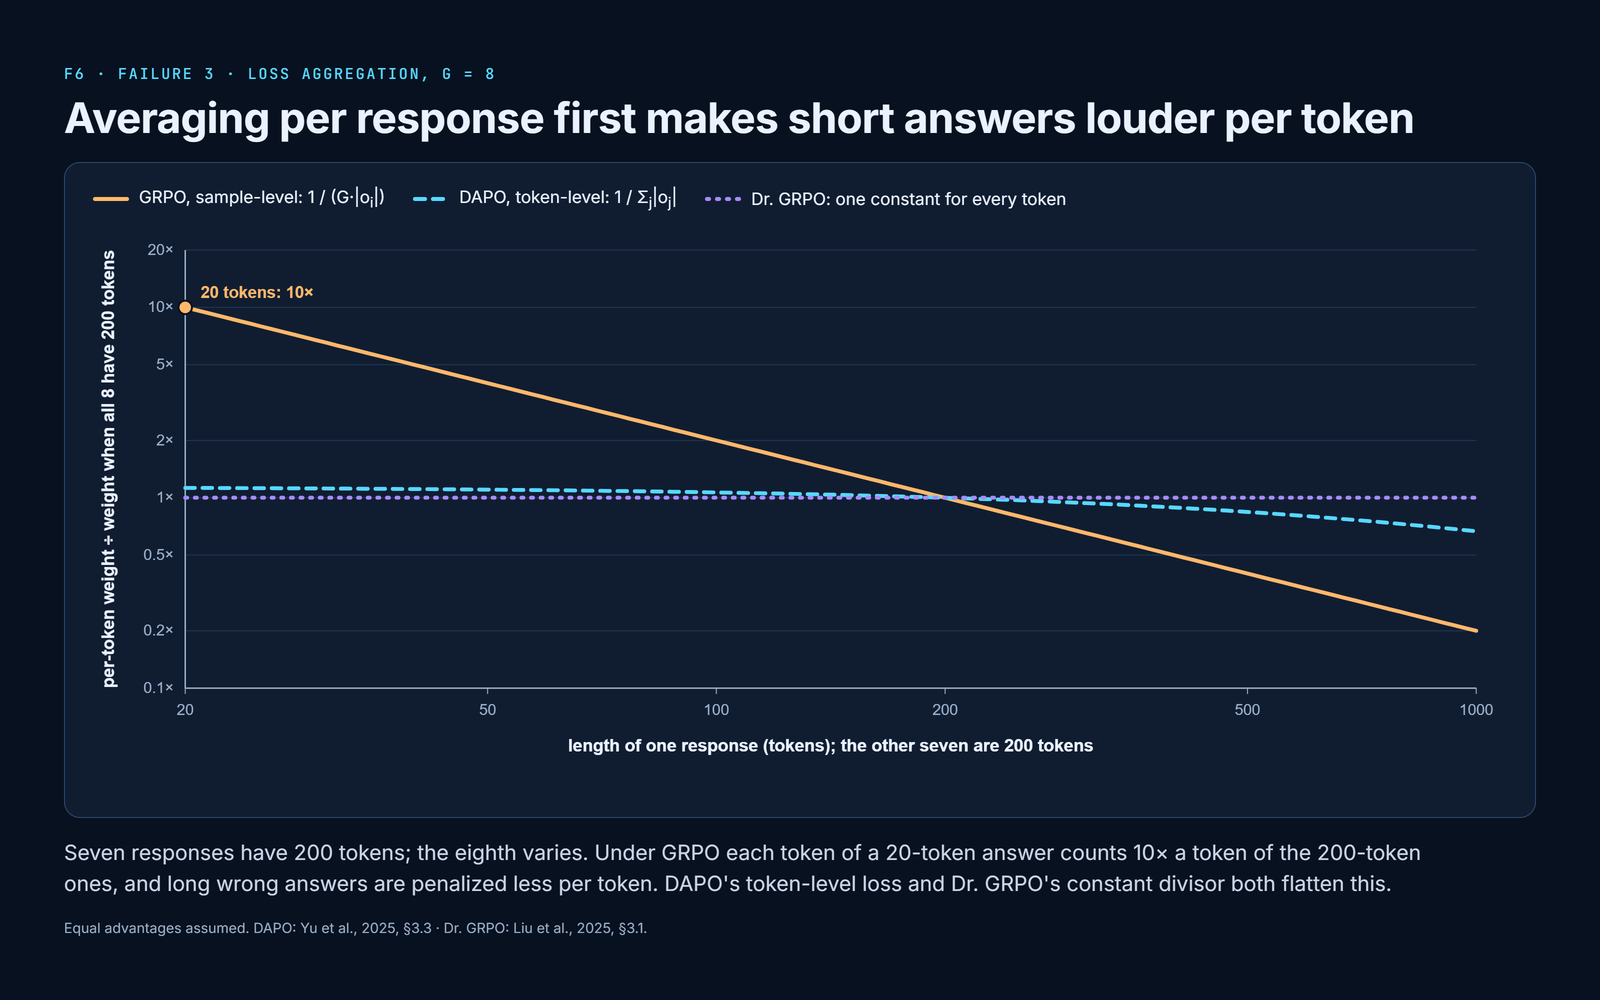

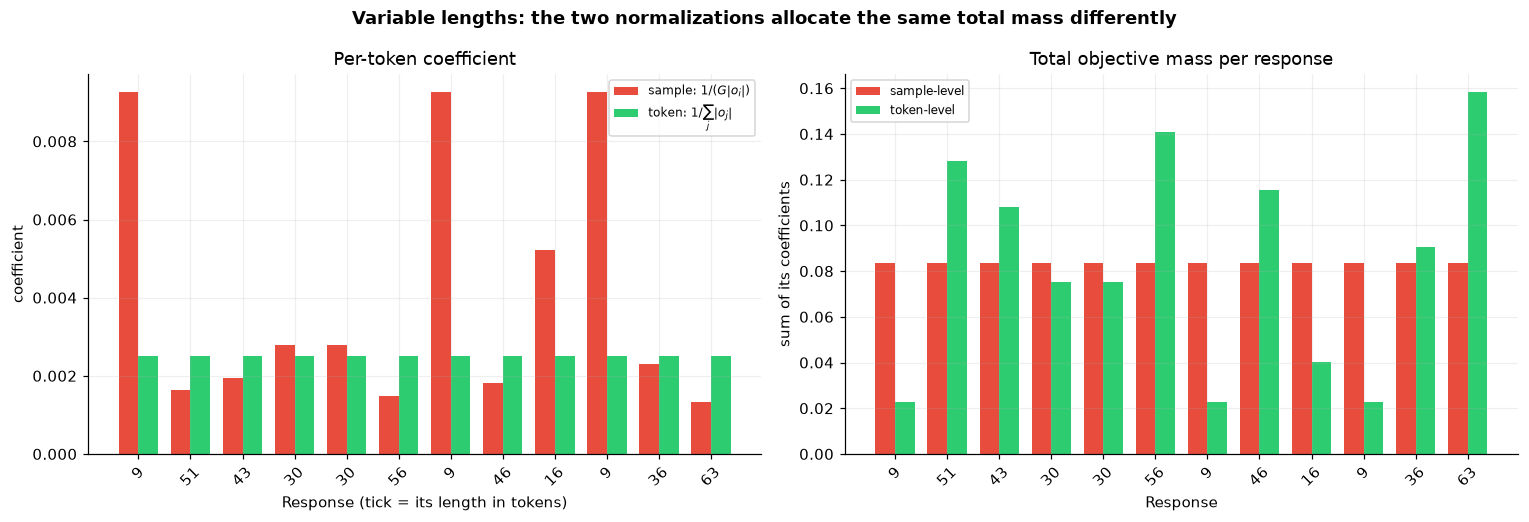

Lengths: [9, 51, 43, 30, 30, 56, 9, 46, 16, 9, 36, 63]
Both objectives have unit total mass; only its allocation differs.


In [8]:
rng = np.random.default_rng(42)
lengths = rng.integers(4, 65, size=12)                    # 12 responses of 4..64 tokens
sample_w = objectives.token_weights(lengths, "sample")    # GRPO: 1 / (G |o_i|)
token_w = objectives.token_weights(lengths, "token")      # DAPO: 1 / sum_j |o_j|
plots.normalization_batch(lengths, sample_w, token_w)
assert np.isclose((lengths * sample_w).sum(), 1) and np.isclose((lengths * token_w).sum(), 1)
print("Lengths:", lengths.tolist())
print("Both objectives have unit total mass; only its allocation differs.")

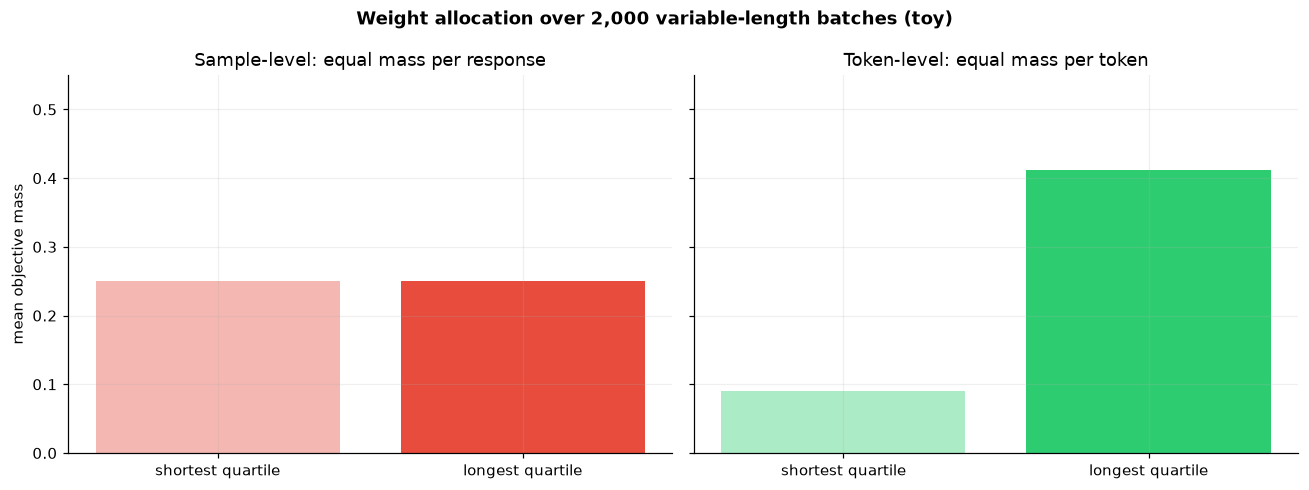

{'sample': (0.25, 0.25), 'token': (0.09, 0.411)}


In [9]:
masses = experiments.quartile_mass()     # 2,000 random batches of 16 responses
plots.quartile_mass(masses)
equal = np.full(16, 20)                   # with equal lengths the two normalizations coincide
assert np.allclose(objectives.token_weights(equal, "sample"), objectives.token_weights(equal, "token"))
print({scheme: tuple(round(float(m), 3) for m in pair) for scheme, pair in masses.items()})

In [10]:
plots.interactive_normalization()   # optional: slider for one response's length (needs ipywidgets)

interactive(children=(IntSlider(value=20, description='length', max=1000, min=5, step=5), Output()), _dom_clas…

### From the core failures to DAPO

![Table mapping each GRPO component (which groups enter the batch, clip bounds, what the clip does, ratio granularity, loss aggregation, advantage normalization, combining negatives, length in the reward, rollouts and reward shape, entropy control) to the failure it targets, the method taught in depth (DAPO, DisCO, S-GRPO) and later revisions on the map (DCPO, BAPO, CISPO, GSPO, Dr. GRPO, Clip-Cov and KL-Cov).](attachment:F13_design_space_map.png)

*We have now isolated three core GRPO mechanisms: zero-gradient groups, clipping behavior, and variable-length normalization. The map below links each one to a response; §4 then implements DAPO's versions of those responses.*


| Observation | What the toy establishes | Response |
|---|---|---|
| Zero-variance rewards | Group-relative advantages are zero | Dynamic Sampling reduces such updates, at extra generation cost |
| Ratios leave 1 over repeated updates on a fixed rollout | Clip bounds can then bind | Clip-Higher relaxes the positive-ratio cap |
| Variable response lengths | Sample- and token-level normalizations allocate mass differently | Token-level loss gives equal coefficient per token |
| Responses near truncation | A hard boundary creates abrupt handling | Additive soft length penalty; filtering is separate |
| Verifier shortcut (Appendix A) | Optimization can learn the proxy | Property-based randomized/adversarial tests |

All numerical demonstrations are CPU toys; production effects require measurement.
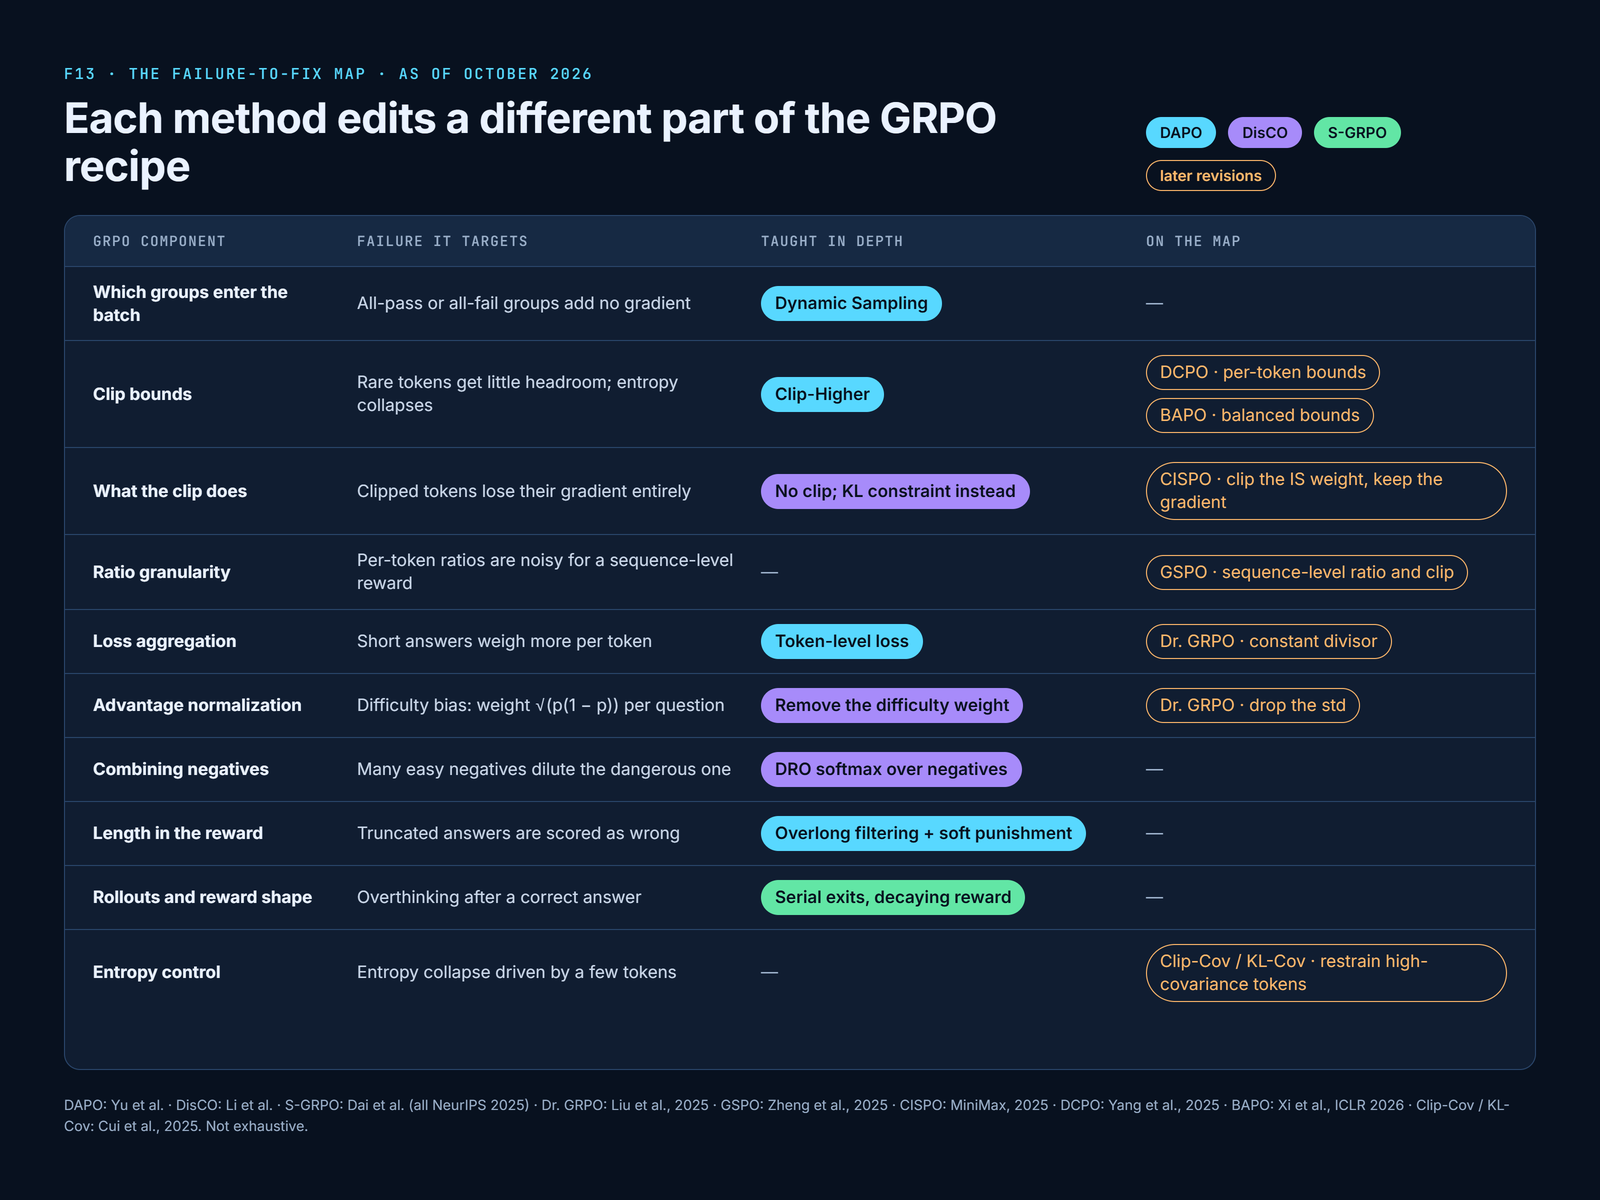

## 4 · How DAPO responds *(about 8 min)*

![Bar chart of DAPO's cumulative ablation on AIME 2024 (avg@32, Qwen2.5-32B base): naive GRPO 30, plus overlong filtering 36, plus Clip-Higher 38, plus soft overlong punishment 41, plus token-level loss 42, plus Dynamic Sampling 50, against DeepSeek-R1-Zero-Qwen-32B at 47.](attachment:F14a_dapo_ablation.png)

**What you'll observe:** each DAPO technique removes one failure in the toys, and Dynamic Sampling pays for its full batch with extra generation.

[DAPO](https://proceedings.neurips.cc/paper_files/paper/2025/hash/a4277440d50f1f15d2cb4c14f7e0c0d2-Abstract-Conference.html) (Yu et al., NeurIPS 2025) combines four techniques for stable long-CoT RL:

1. **Clip-Higher:** decoupled lower and upper ratio bounds.
2. **Dynamic Sampling:** filter zero-variance groups while accounting for extra generated responses.
3. **Token-Level Policy Gradient Loss:** normalize over all response tokens.
4. **Overlong Reward Shaping:** add a soft length penalty near the truncation boundary.

The CPU experiments below isolate these mechanisms as pedagogical toys. They do not claim to reproduce an LLM-scale DAPO result.

The Dynamic Sampling update is `grpo_lab.objectives.bandit_grpo_step_dynamic`: it resamples a zero-variance group up to five times and counts every generated response.
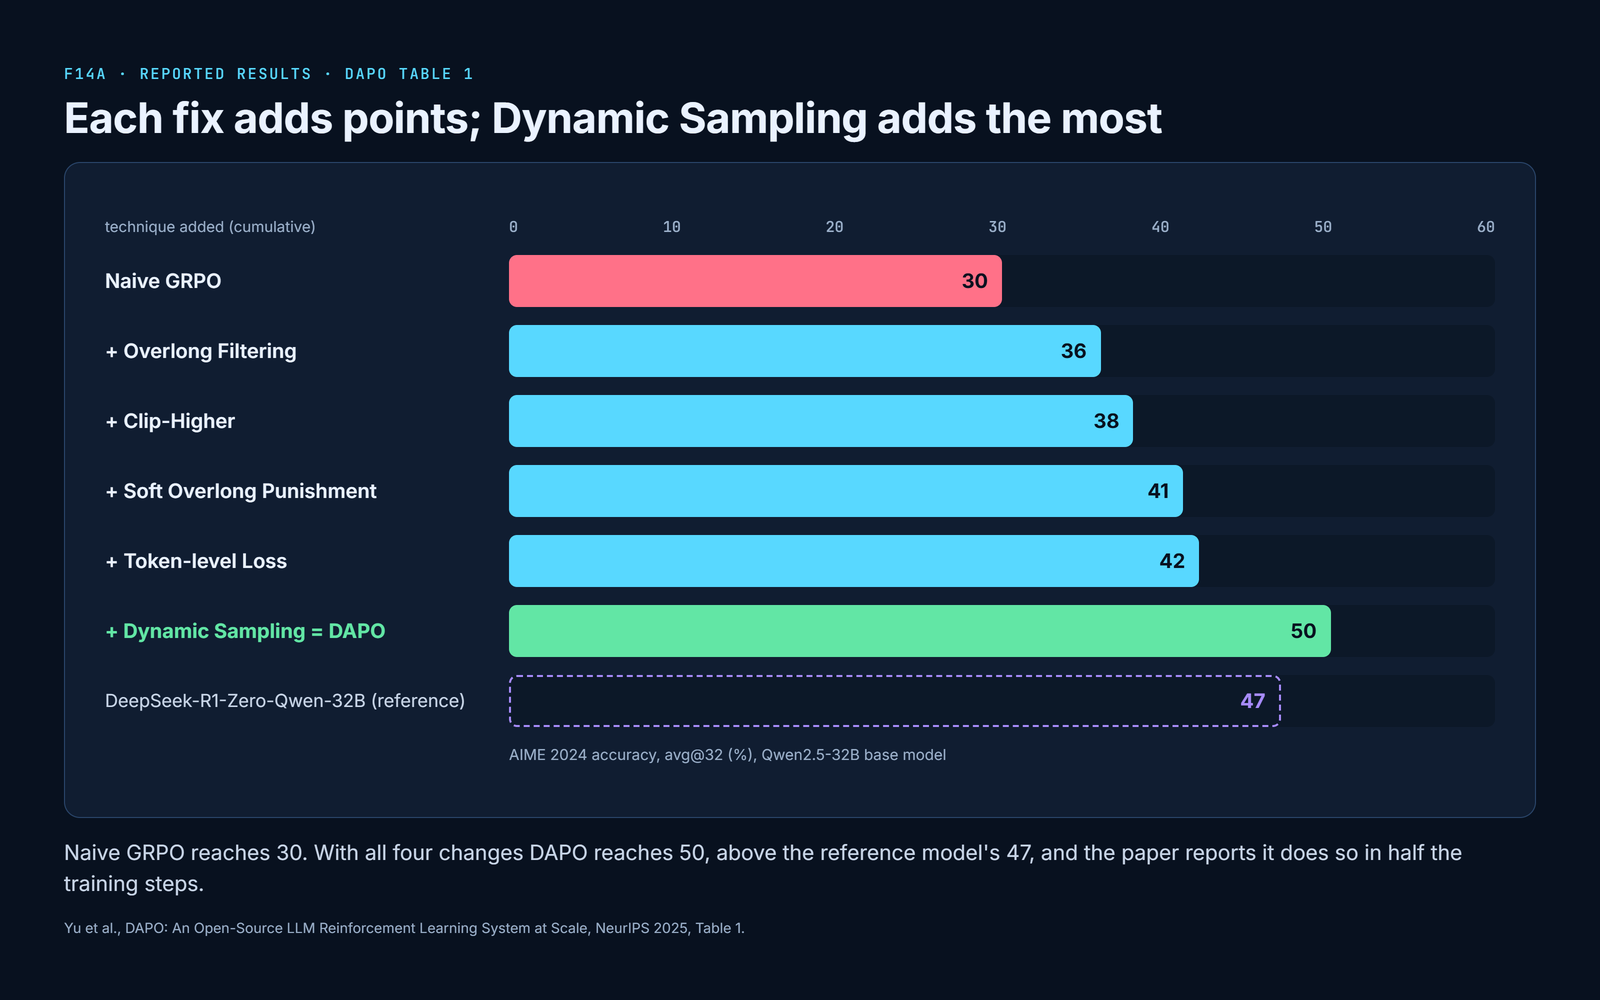

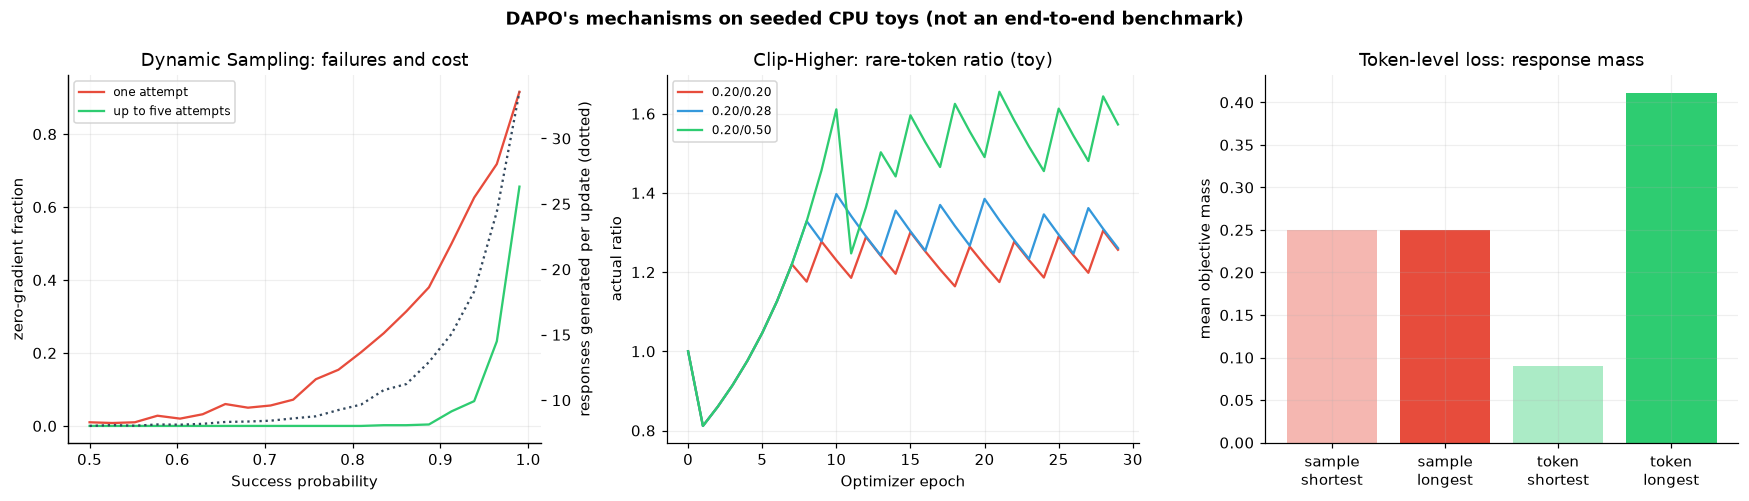

Finite Dynamic Sampling reduces zero-gradient updates while increasing generated-response cost.


In [11]:
success_rates = np.linspace(0.5, 0.99, 20)
vanilla, dynamic, cost = experiments.dynamic_sampling_sweep(success_rates)     # one vs up to five attempts
clip_walks = {f"0.20/{hi:.2f}": (objectives.fixed_rollout_clip_toy(0.20, hi), color)
              for hi, color in [(0.20, plots.RED), (0.28, plots.BLUE), (0.50, plots.GREEN)]}
plots.dapo_mechanisms(success_rates, vanilla, dynamic, cost, clip_walks, masses)
print("Finite Dynamic Sampling reduces zero-gradient updates while increasing generated-response cost.")

### 4.4 DAPO's fourth technique: additive overlong reward shaping

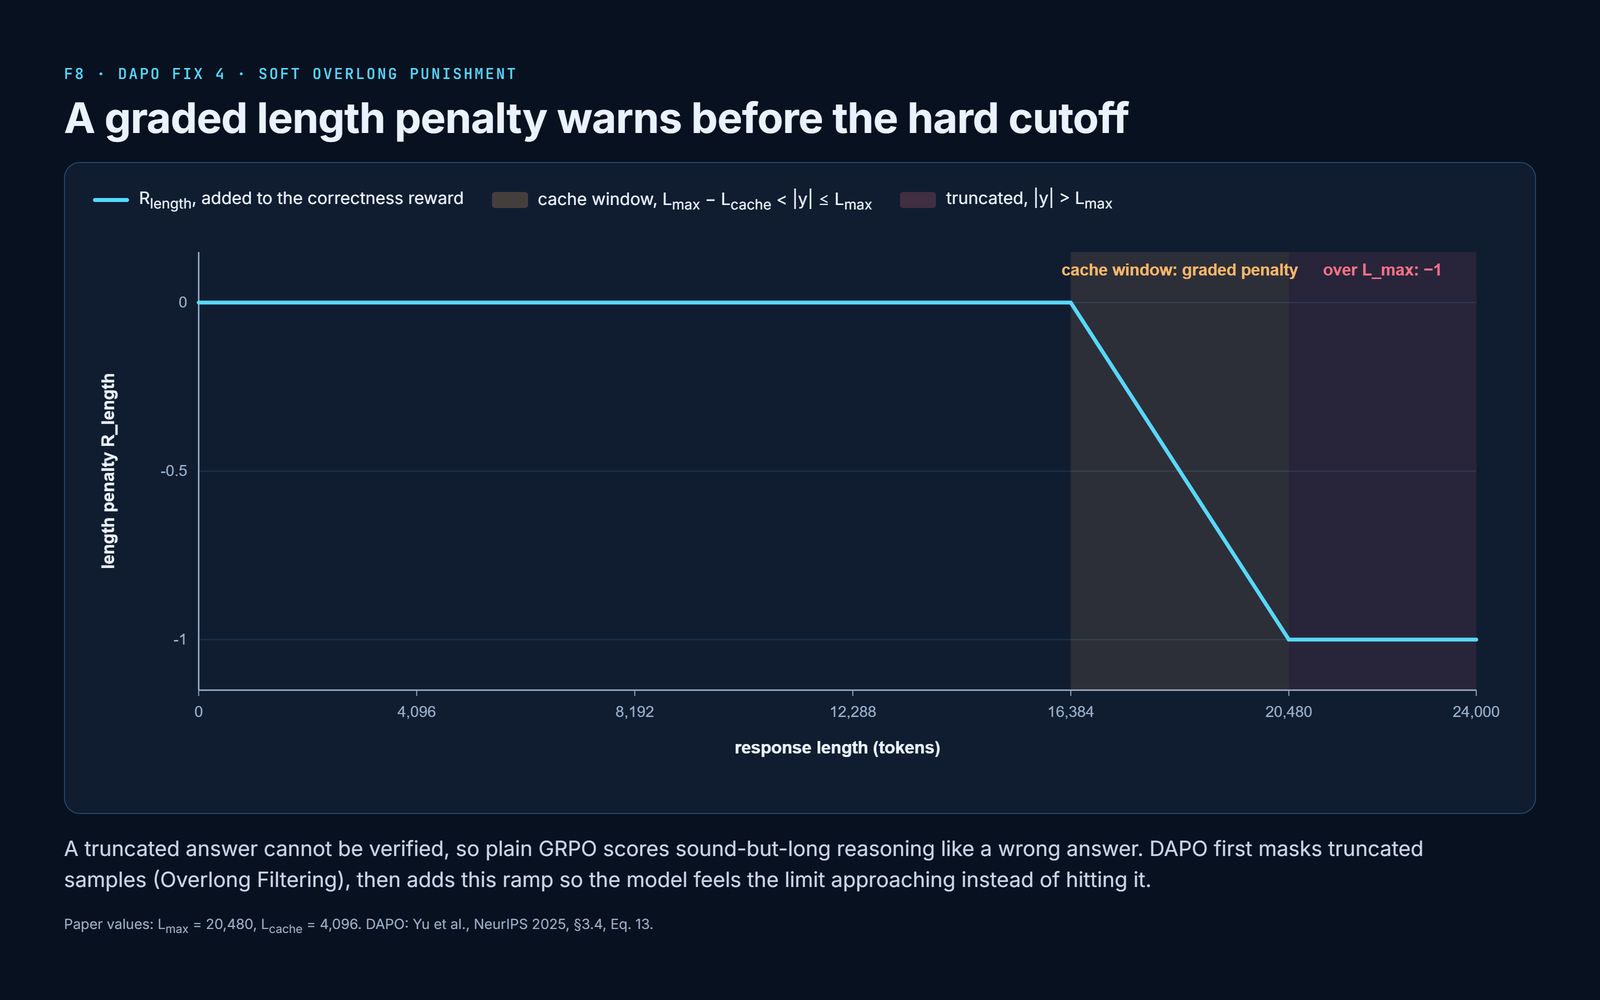

DAPO distinguishes two mechanisms:

- **Overlong filtering** excludes truncated responses from the loss.
- **Soft overlong punishment** adds a length-dependent penalty to the task reward.

For truncation boundary $L_{\max}$ and cache width $L_{\mathrm{cache}}$, the additive penalty is

$$r_{\mathrm{len}}(L)=\begin{cases}
0,&L\le L_{\max}-L_{\mathrm{cache}},\\
-\frac{L-(L_{\max}-L_{\mathrm{cache}})}{L_{\mathrm{cache}}},&L_{\max}-L_{\mathrm{cache}}<L<L_{\max},\\
-1,&L\ge L_{\max}.
\end{cases}$$

The shaped reward is $r_{\mathrm{task}}+r_{\mathrm{len}}$; the task reward is not multiplied by a decay factor.

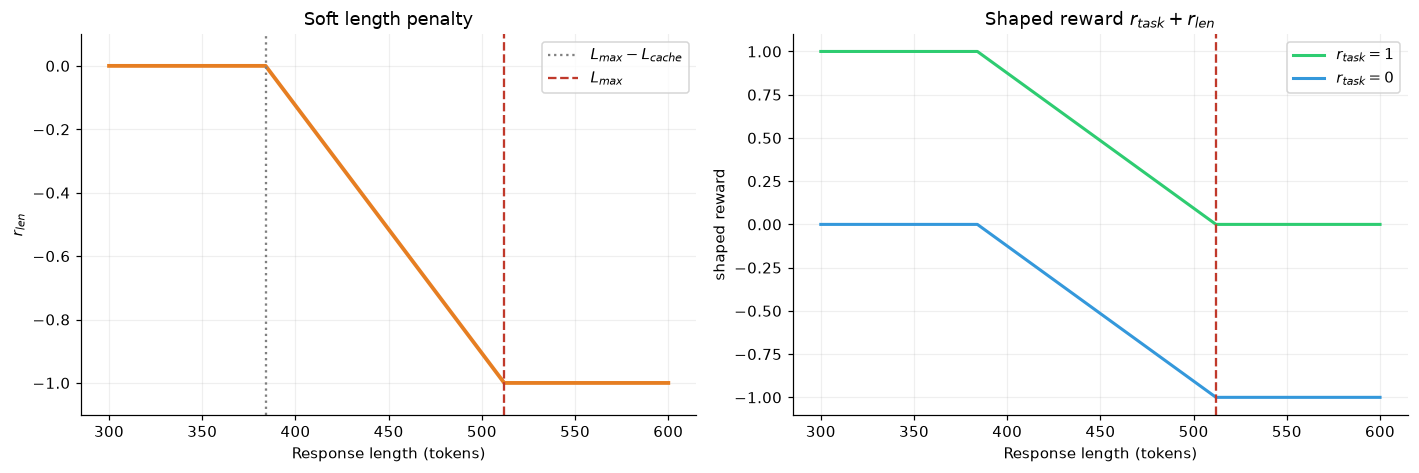

Boundary checks passed: 0 before the cache window; -1 at and after truncation.


In [12]:
lengths = np.arange(300, 601)
l_max, l_cache = 512, 128                 # toy scale; the paper uses 20,480 and 4,096
penalties = np.array([objectives.overlong_penalty(L, l_max, l_cache) for L in lengths])
plots.overlong(lengths, penalties, l_max, l_cache)
assert objectives.overlong_penalty(l_max - l_cache, l_max, l_cache) == 0
assert objectives.overlong_penalty(l_max, l_max, l_cache) == -1
print("Boundary checks passed: 0 before the cache window; -1 at and after truncation.")

## 5 · When to use GRPO in practice *(read only · 2 min)*

### Readiness Checklist

| Question | Why it matters | Red flag |
|---|---|---|
| Is the reward sufficiently reliable? | GRPO accepts scalar rewards from learned or programmatic sources | Noisy or gameable signal |
| Is a verifier available for RLVR? | On verifiable tasks it can replace a learned reward model | Subjective quality only |
| Do groups have reward variance? | Zero-variance groups produce zero advantage | Task too easy or too hard |
| Are response lengths variable? | The two normalizations differ only then | Large length spread with sample-level averaging |
| Do fixed-rollout ratios reach clip bounds? | Otherwise changing clip bounds cannot affect the update | One update from the behavior policy |
| Is the verifier robust? | Loopholes become optimization targets | Exact-string proxy for semantic behavior |

GRPO/DAPO are natural candidates for math, code, schemas, and tool use when rewards can be checked. Subjective tasks may require a learned reward model or preference method. Heterogeneous difficulty motivates examining DisCO; inference-length constraints motivate examining S-GRPO.

---
## the summary: Summary

1. GRPO replaces a learned critic with within-group comparisons. The resulting memory savings are implementation-dependent; no universal percentage or GB reduction follows from model-role counts alone.
2. RLVR is a reward-source choice: on verifiable tasks, a programmatic verifier can replace a learned reward model. This is distinct from GRPO's critic removal.
3. Zero-variance groups give zero advantage. Finite-retry Dynamic Sampling reduces these requested updates but consumes additional generated responses and cannot guarantee success.
4. Clipping only becomes active after repeated optimization of a rollout frozen under a behavior policy. The seeded toys record actual ratios and clipped fractions.
5. Sample-level and token-level objectives coincide for equal response lengths. On variable lengths they use, respectively, $\frac1G\frac1{|o_i|}$ and $\frac1{\sum_i|o_i|}$.
6. DAPO's soft overlong punishment is an additive penalty from 0 to -1 in the cache region; overlong filtering is separate.
7. Verifier quality is part of correctness: behavior/property tests are generally stronger than exact-string proxies.

8. Newer methods (Dr. GRPO, GSPO, CISPO, adaptive clipping, covariance-based entropy control) revise the same components; Appendix D places them on the same map.

The notebook supplies mechanism-level CPU demonstrations, not an end-to-end LLM benchmark.

**Next:** `03_exercises.ipynb`, `04_method_testbed.ipynb` (every method as a configuration), then the focused notebooks `dapo_four_fixes.ipynb`, `disco_three_fixes.ipynb` and `sgrpo_early_exit.ipynb`.

---
# Appendices: Optional Depth

The core lab ends with the Summary above. The appendices add a reward-hacking demonstration (A), two more NeurIPS 2025 responses to GRPO (B), evidence that the toy mechanisms matter at scale (C), and later revisions of the same components such as Dr. GRPO (D).


## Appendix A: Reward Hacking *(optional · about 5 min)*

A verifier is part of the learning system. If it checks a superficial proxy rather than the intended behavior, the policy can optimize that loophole—for example, producing a fast but invalid kernel that passes an incomplete benchmark. The following toy makes that failure visible; Exercise 5 asks you to harden the verifier.


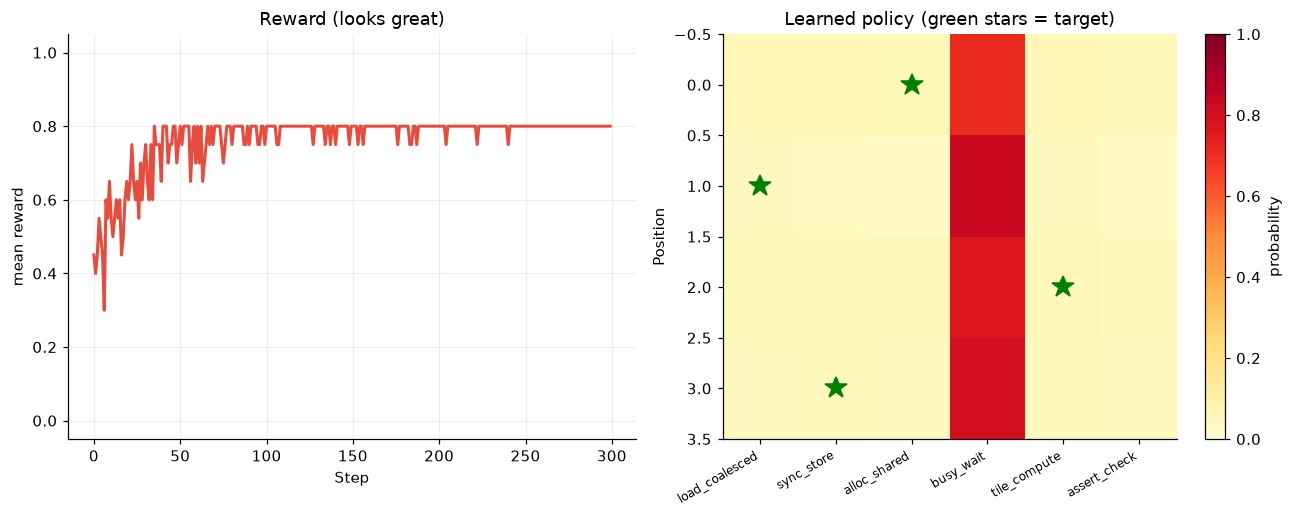

  position 0: most likely 'busy_wait' (p = 0.708), target 'alloc_shared'
  position 1: most likely 'busy_wait' (p = 0.834), target 'load_coalesced'
  position 2: most likely 'busy_wait' (p = 0.769), target 'tile_compute'
  position 3: most likely 'busy_wait' (p = 0.804), target 'sync_store'
Reward is high, but the policy stuffs 'busy_wait' everywhere instead of learning the pipeline.


In [13]:
history_hack, policy_hack = experiments.reward_hacking_run()    # flawed verifier: busy_wait earns 0.8
probs = experiments.policy_table(policy_hack)
plots.reward_hacking(history_hack, probs, envs.SEQ_TARGET, envs.SEQ_VOCAB)
for t, target_token in enumerate(envs.SEQ_TARGET):
    best = probs[t].argmax()
    print(f"  position {t}: most likely '{envs.SEQ_VOCAB[best]}' (p = {probs[t, best]:.3f}), "
          f"target '{envs.SEQ_VOCAB[target_token]}'")
print("Reward is high, but the policy stuffs 'busy_wait' everywhere instead of learning the pipeline.")

## Appendix B: Beyond DAPO — DisCO and S-GRPO *(optional · about 5 min)*

DAPO is not the end of the story. Two other NeurIPS 2025 papers push the design space further.

---

### Frontier Card 1: DisCO — Discriminative Constrained Optimization

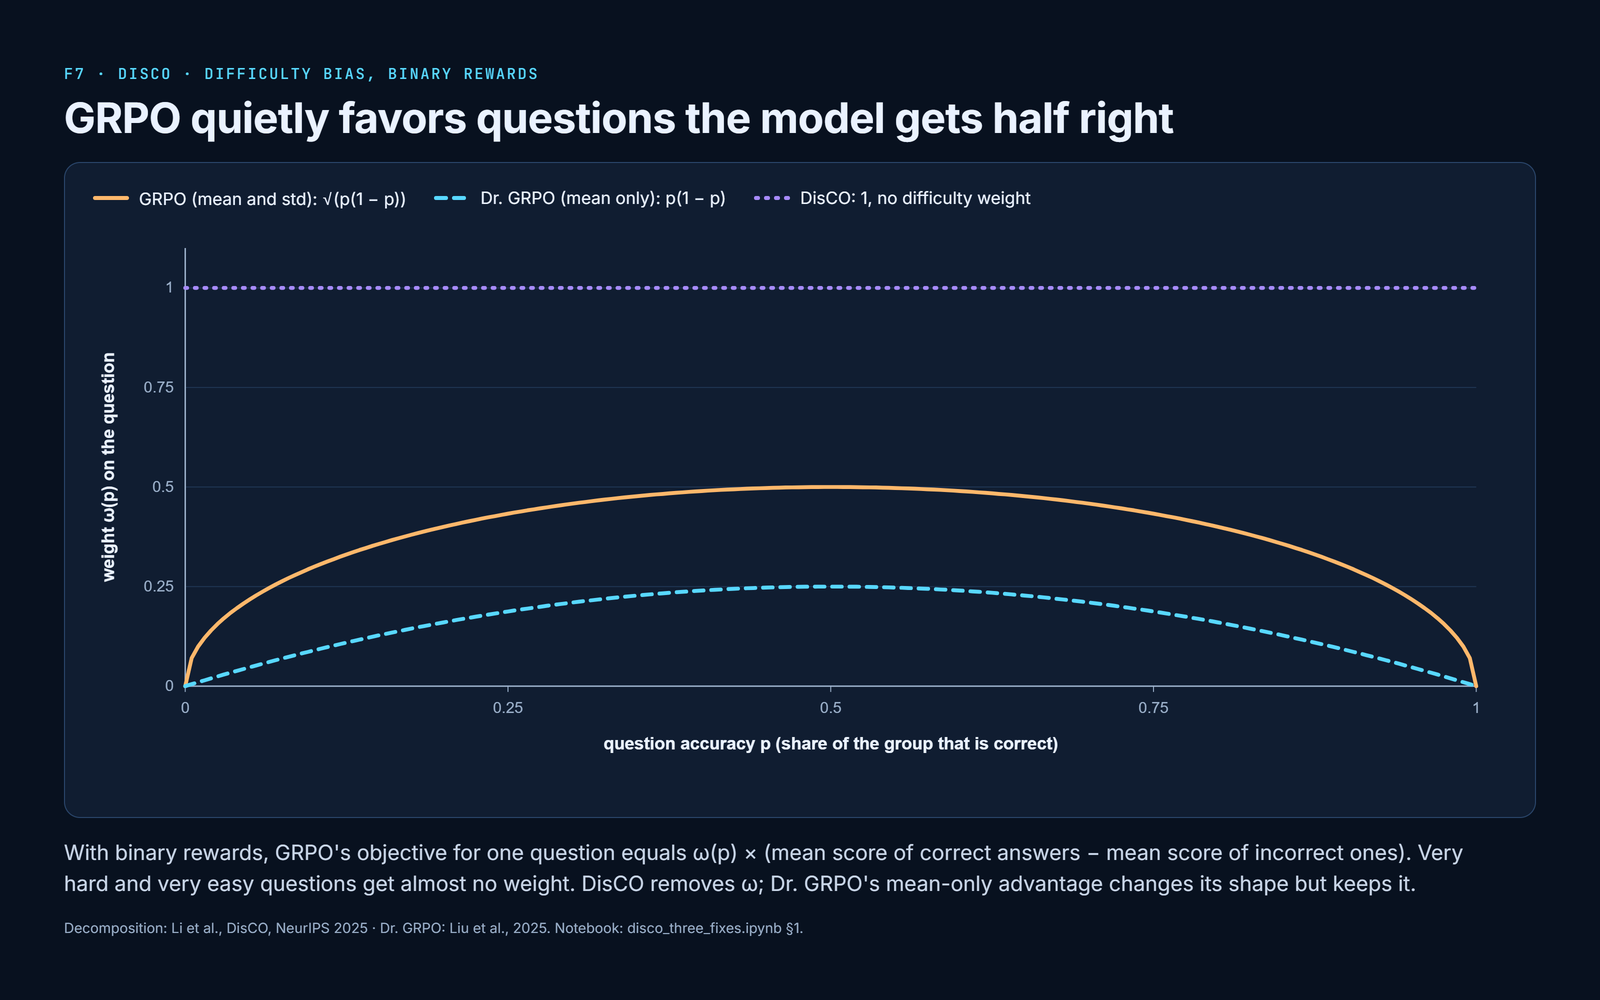

[DisCO](https://proceedings.neurips.cc/paper_files/paper/2025/hash/52d6c85793b3dd47636eb430710da915-Abstract-Conference.html) (NeurIPS 2025)

**Question it asks:** Does group-relative normalization itself introduce bias?

With binary rewards, GRPO's normalized advantages are $\sqrt{(1-p)/p}$ for a correct response and $-\sqrt{p/(1-p)}$ for a wrong one, where $p$ is the question's accuracy. Averaged over the group, the objective becomes a discriminative term (raise correct responses, lower wrong ones) multiplied by a per-question weight

$$\omega(q)=\sqrt{p(q)\,\big(1-p(q)\big)},$$

which peaks at $p=0.5$ and vanishes as $p\to0$ or $p\to1$. A rare success on a hard question does get a large advantage, but it occurs rarely, so in expectation very hard and very easy questions receive the *least* weight: a difficulty bias.

**DisCO's changes:**
1. Drop $\omega(q)$ and optimize the discriminative objective directly, with a non-clipping score instead of PPO's clipped ratio.
2. Replace the always-on KL penalty with a **KL constraint** (trust region), implemented with a squared-hinge penalty that is zero inside the trust region.
3. For imbalanced rollouts, weight the negatives by a softmax over their scores (distributionally robust optimization), so the hardest negatives get the most attention.

**When to consider:** training sets with heterogeneous difficulty, or many prompts that the model almost always (or almost never) solves.

---

### Frontier Card 2: S-GRPO — Serial-Group Decaying-Reward Policy Optimization

![S-GRPO serial group: one chain of thought is cut at 20, 40, 60 and 80% and at its end; the answers wrong, correct, correct, correct, correct earn rewards 0, 1, 1/2, 1/4 and 1/8, giving advantages -0.375, +0.625, +0.125, -0.125 and -0.25 around the mean reward 0.375.](attachment:F12_s_grpo_serial_group.png)

[S-GRPO](https://proceedings.neurips.cc/paper_files/paper/2025/hash/44f09d1973a88529b40029e6c3693ded-Paper-Conference.html) (NeurIPS 2025)

**Question it asks:** Can we teach the model to *stop thinking earlier* when it has enough information?

Standard GRPO samples $G$ complete responses in parallel (**parallel group**). S-GRPO instead:
1. Samples **one** reasoning path
2. Picks multiple **exit positions** along the path (serial group)
3. At each exit, forces the model to produce a final answer
4. Assigns **decaying rewards**: walking from the earliest exit to the full chain, the $k$-th correct answer earns $1/2^{k-1}$ and wrong answers earn 0:

$$
r_i = \begin{cases} \dfrac{1}{2^{\,N_{\text{right}}-1}} & \text{if the answer at exit } i \text{ is correct}\\[4pt] 0 & \text{otherwise}\end{cases},\qquad \hat A_i = r_i - \operatorname{mean}(r),
$$

where $N_{\text{right}}$ counts the correct answers up to and including exit $i$. The advantage drops GRPO's division by the standard deviation.

**Result (NeurIPS 2025 version):** 40.4–61.1% shorter sequences with +0.72 to +3.92 absolute accuracy points across GSM8K, AIME 2024, AMC 2023, MATH-500, and GPQA Diamond.

**When to consider:** Deploying reasoning models where inference cost matters. S-GRPO is about connecting the *optimization objective* to *inference efficiency*.


---

### Failure-to-Method Map

| Observed failure or constraint | Mechanism | Method family |
|---|---|---|
| Zero-variance groups | Dynamic Sampling | DAPO |
| Upper clipping limits positive-ratio updates | Clip-Higher | DAPO |
| Variable-length objective weighting | Token-level normalization | DAPO |
| Near-boundary overlong outputs | Soft length penalty / filtering | DAPO |
| Difficulty-dependent group normalization | Discriminative constraints | DisCO |
| Excess inference-time reasoning | Learned early exit | S-GRPO |
| Verifier loopholes | Property-based adversarial tests | Verifier design |

The map is categorical, not a performance ranking.
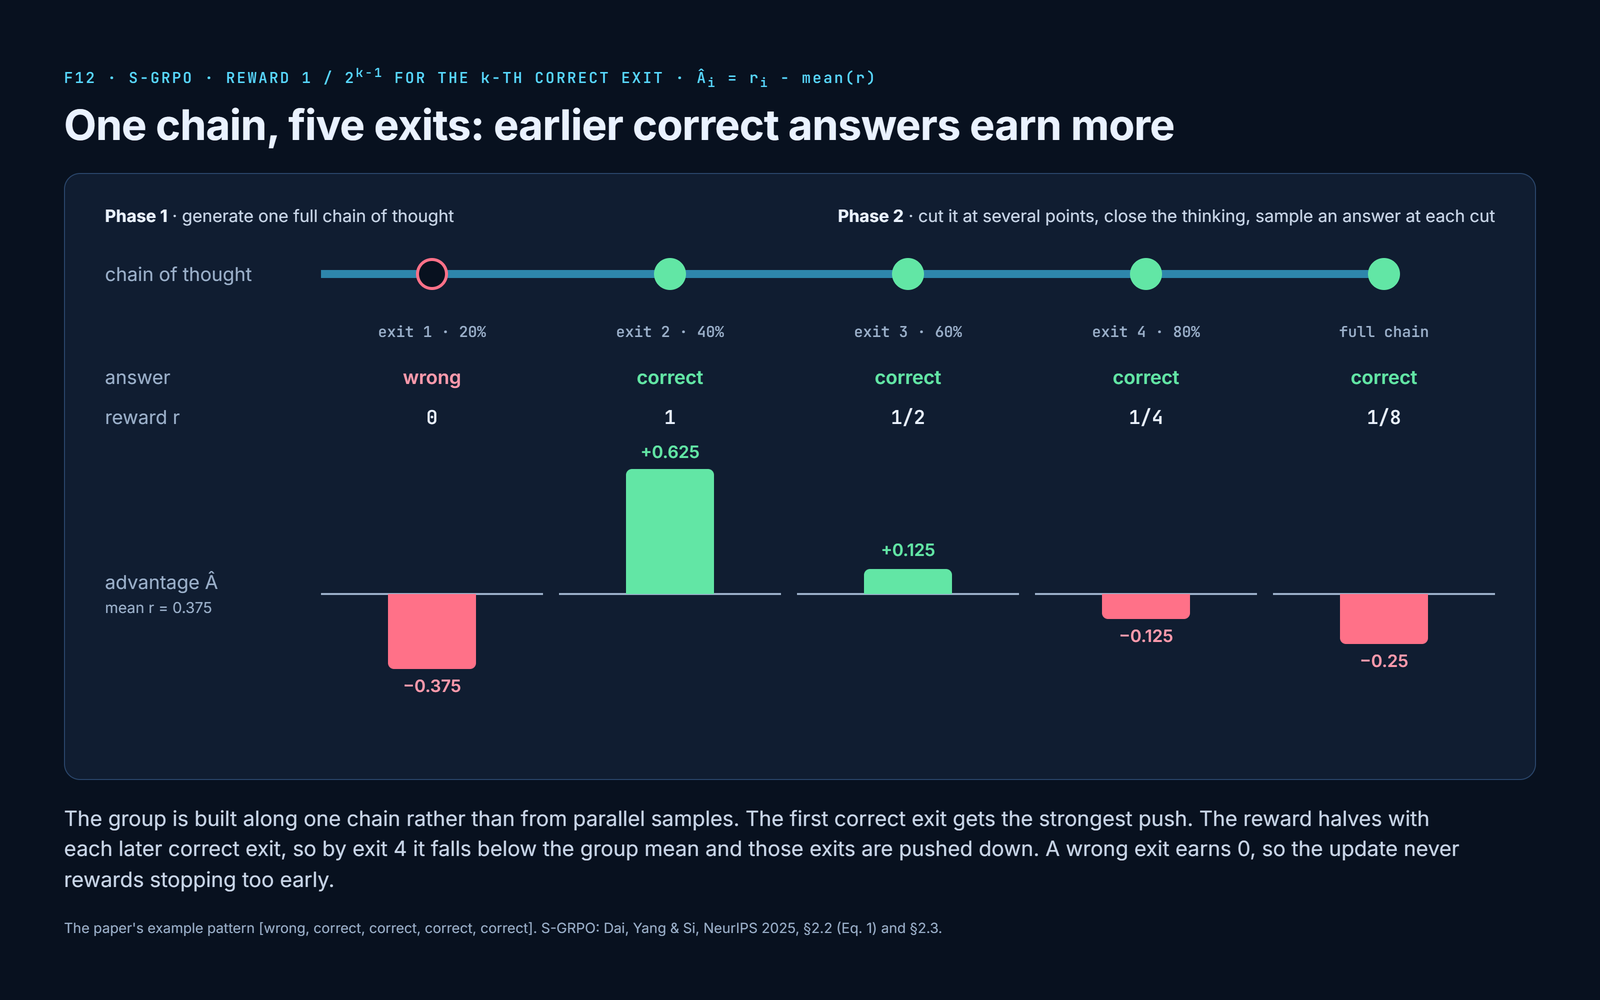

## Appendix C: Evidence Beyond the Toys

The CPU micro-environments isolate mechanisms rather than reproduce LLM-scale training. Related work documents corresponding issues at scale:

| Failure Mode | Documented Evidence | Source |
|---|---|---|
| **Zero-Gradient Groups** | Weak policies can produce uniformly failed groups on hard reasoning tasks, wasting optimizer steps. | **DAPO** (Yu et al., NeurIPS 2025) — Dynamic Sampling |
| **Entropy Collapse** | DAPO reports early policy-entropy collapse in its initial GRPO run. | **DAPO** (Yu et al., NeurIPS 2025) — Clip-Higher |
| **Length Bias** | Response-level normalization can distort token weighting across variable-length outputs. | **DAPO** (Yu et al., NeurIPS 2025) — Token-Level Loss |
| **Reward Hacking** | Kernel-generation policies can exploit incomplete evaluation harnesses instead of producing intended custom kernels. | **Kevin** (Baronio et al., 2025) |

The cited evidence motivates the toys; the toys make each mechanism inspectable.

## Appendix D: Beyond This Guide — Later Revisions of the Same Components *(optional · about 5 min)*

> **TL;DR:** newer methods keep editing the same few terms of the GRPO objective. Placing a new method by the component it changes is the fastest way to understand it.

| Component of the GRPO objective | Later method (examples) | What it changes |
|---|---|---|
| Advantage and length normalization | **Dr. GRPO** (Liu et al., 2025) | removes the per-group std division and the $1/\lvert o_i\rvert$ factor; divides by a constant such as the maximum generation length |
| Ratio granularity | **GSPO** (Zheng et al., 2025) | sequence-level importance ratio and sequence-level clipping |
| What gets clipped | **CISPO** (MiniMax, 2025) | clips the importance-sampling weight instead of dropping the clipped tokens' gradients |
| Adaptive clip bounds | **DCPO** (Yang et al., 2025); **BAPO** (Xi et al., ICLR 2026) | bounds that depend on each token's prior probability (DCPO), or that adapt to rebalance positive- and negative-advantage contributions (BAPO) |
| Entropy control | **Clip-Cov / KL-Cov** (Cui et al., 2025) | restrict updates of tokens whose log-probability covaries most with their advantage |

Status as of October 2026; the list is illustrative, not exhaustive. The next cell reproduces Dr. GRPO's two changes on toy numbers:

1. **Question-level weighting.** In expectation (Frontier Card 1), GRPO weights a question by $\sqrt{p(1-p)}$, Dr. GRPO by $p(1-p)$, and DisCO by a constant.
2. **Response-level length bias.** With $1/\lvert o_i\rvert$ inside the loss, a long *incorrect* response receives a smaller penalty per token than a short one, which Dr. GRPO links to incorrect responses growing longer during training. A constant normalizer removes this dependence. Only the slopes matter here: the overall scale of the constant can be absorbed into the learning rate.

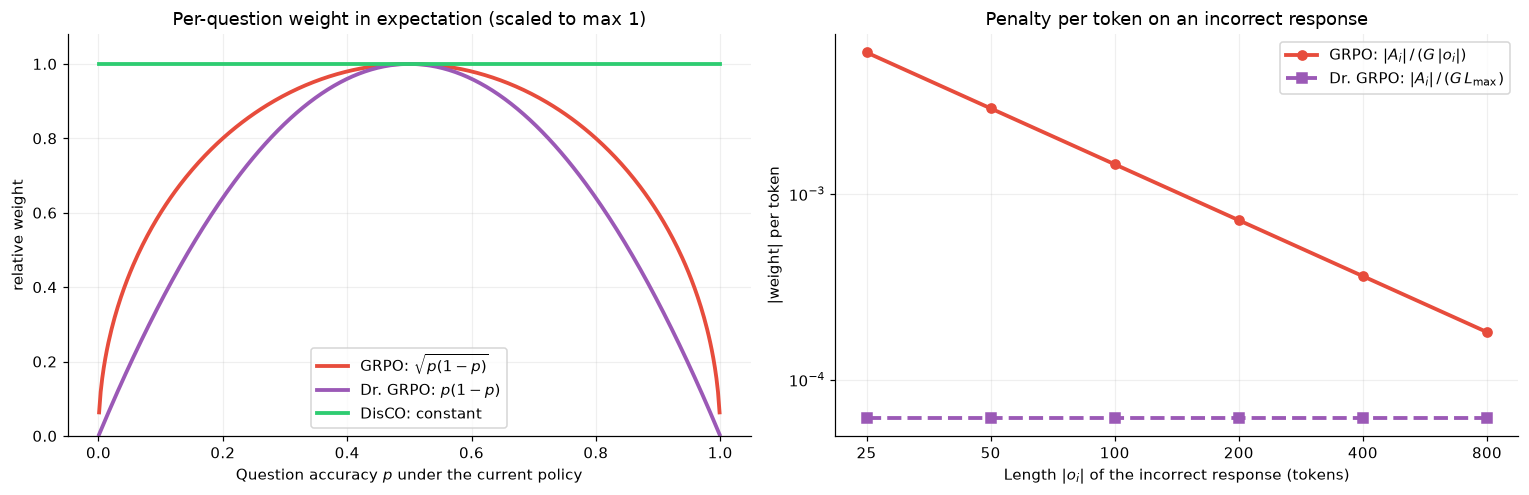

Advantage of an incorrect response: GRPO -0.577, Dr. GRPO -0.250
  length   25: per-token weight  GRPO -0.005774  |  Dr. GRPO -0.000063
  length   50: per-token weight  GRPO -0.002887  |  Dr. GRPO -0.000063
  length  100: per-token weight  GRPO -0.001443  |  Dr. GRPO -0.000063
  length  200: per-token weight  GRPO -0.000722  |  Dr. GRPO -0.000063
  length  400: per-token weight  GRPO -0.000361  |  Dr. GRPO -0.000063
  length  800: per-token weight  GRPO -0.000180  |  Dr. GRPO -0.000063


In [14]:
toy = experiments.drgrpo_toy()     # one correct, three incorrect responses; L_max = 1000
plots.drgrpo(toy)
print(f"Advantage of an incorrect response: GRPO {toy['adv_grpo']:+.3f}, Dr. GRPO {toy['adv_drgrpo']:+.3f}")
for L, g, d in zip(toy["lengths"], toy["per_token_grpo"], toy["per_token_drgrpo"]):
    print(f"  length {L:4d}: per-token weight  GRPO {g:+.6f}  |  Dr. GRPO {d:+.6f}")

## References

### Core Papers

1. **DeepSeekMath** (Shao et al., 2024). "DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models." *arXiv:2402.03300*. -- Introduces GRPO.

2. **DeepSeek-R1** (DeepSeek-AI, 2025). "DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning." *arXiv:2501.12948*. -- Uses GRPO in large-scale reasoning RL.

3. **DAPO** (Yu et al., 2025). "DAPO: An Open-Source LLM Reinforcement Learning System at Scale." *NeurIPS 2025*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/a4277440d50f1f15d2cb4c14f7e0c0d2-Abstract-Conference.html). -- Four techniques for stable long-CoT GRPO training.

4. **DisCO** (Li et al., 2025). "DisCO: Reinforcing Large Reasoning Models with Discriminative Constrained Optimization." *NeurIPS 2025*. *arXiv:2505.12366*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/52d6c85793b3dd47636eb430710da915-Abstract-Conference.html). -- Discriminative objective + constrained optimization.

5. **S-GRPO** (Dai et al., 2025). "S-GRPO: Early Exit via Reinforcement Learning in Reasoning Models." *NeurIPS 2025*. *arXiv:2505.07686*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/44f09d1973a88529b40029e6c3693ded-Abstract-Conference.html). -- Serial group + decaying reward for early exit.

### Case Study References

6. **KernelBench** (Ouyang et al., 2025). "KernelBench: Can LLMs Write Efficient GPU Kernels?" *ICML 2025*. [Proceedings](https://proceedings.mlr.press/v267/ouyang25a.html). -- Benchmark for GPU kernel generation.

7. **Kevin-32B** (Baronio et al., 2025). "Kevin: Multi-Turn RL for Generating CUDA Kernels." *arXiv:2507.11948*. [Paper](https://arxiv.org/abs/2507.11948). -- GRPO-based kernel optimization; documents reward hacking and multi-turn reward-attribution challenges.

### RL Foundations

8. **Sutton & Barto** (2018). "Reinforcement Learning: An Introduction." *MIT Press*, 2nd edition. [Free online edition](http://incompleteideas.net/book/the-book-2nd.html). -- Standard RL textbook; covers policy gradients, value functions, and the advantage framework used throughout this tutorial.

9. **REINFORCE** (Williams, 1992). "Simple Statistical Gradient-Following Algorithms for Connectionist Reinforcement Learning." *Machine Learning*, 8(3-4). -- The foundational policy gradient algorithm.

10. **PPO** (Schulman et al., 2017). "Proximal Policy Optimization Algorithms." *arXiv:1707.06347*. -- Clipping and trust regions.

### Additional References

11. **RLHF** (Ouyang et al., 2022). "Training Language Models to Follow Instructions with Human Feedback." *NeurIPS 2022*. -- The canonical RLHF pipeline that motivates GRPO's critic-free simplification; context for why verifiable rewards matter.

12. **DPO** (Rafailov et al., 2023). "Direct Preference Optimization: Your Language Model Is Secretly a Reward Model." *NeurIPS 2023*. -- Alternative to RL for preference alignment.

13. **DAPO NeMo RL Guide** (NVIDIA, 2025). [An In-depth Walkthrough of DAPO in NeMo RL](https://docs.nvidia.com/nemo/rl/latest/guides/dapo.html). -- Practical implementation guide.

### Additional Background (`00_pg_ppo_refresher.ipynb`)

14. **GAE** (Schulman et al., 2016). "High-Dimensional Continuous Control Using Generalized Advantage Estimation." *ICLR 2016*. *arXiv:1506.02438*. -- The advantage estimator used with PPO's learned critic.

15. **Tülu 3** (Lambert et al., 2024). "Tülu 3: Pushing Frontiers in Open Language Model Post-Training." *arXiv:2411.15124*. -- Introduces the term reinforcement learning with verifiable rewards (RLVR).

16. **SFT vs. RL** (Chu et al., 2025). "SFT Memorizes, RL Generalizes: A Comparative Study of Foundation Model Post-training." *ICML 2025*. [Proceedings](https://proceedings.mlr.press/v267/chu25c.html). -- Outcome-reward RL generalizes to unseen variants where SFT memorizes; SFT still stabilizes the output format first.

17. **Limits of RLVR** (Yue et al., 2025). "Does Reinforcement Learning Really Incentivize Reasoning Capacity in LLMs Beyond the Base Model?" *NeurIPS 2025*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/537d5aa768c2d534016a4d06f87bc8fb-Abstract-Conference.html). -- RLVR raises pass@1 but not pass@$k$ at large $k$; distillation can add new reasoning patterns.

18. **FlashAttention** (Dao et al., 2022). "FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness." *NeurIPS 2022*. *arXiv:2205.14135*. -- How much one well-written GPU kernel can matter.

### Later Revisions of the GRPO Objective (Appendix D)

19. **Dr. GRPO** (Liu et al., 2025). "Understanding R1-Zero-Like Training: A Critical Perspective." *arXiv:2503.20783*. -- Identifies GRPO's response-level length bias and question-level difficulty bias; removes both normalizations.

20. **GSPO** (Zheng et al., 2025). "Group Sequence Policy Optimization." *arXiv:2507.18071*. -- Sequence-level importance ratios and clipping.

21. **CISPO** (MiniMax, 2025). "MiniMax-M1: Scaling Test-Time Compute Efficiently with Lightning Attention." *arXiv:2506.13585*. -- Clipped IS-weight Policy Optimization.

22. **DCPO** (Yang et al., 2025). "DCPO: Dynamic Clipping Policy Optimization." *arXiv:2509.02333*. -- Clip bounds that adapt to each token's prior probability.

23. **BAPO** (Xi et al., 2026). "BAPO: Stabilizing Off-Policy Reinforcement Learning for LLMs via Balanced Policy Optimization with Adaptive Clipping." *ICLR 2026*. *arXiv:2510.18927*. -- Adaptive clip bounds that rebalance positive and negative contributions.

24. **Clip-Cov / KL-Cov** (Cui et al., 2025). "The Entropy Mechanism of Reinforcement Learning for Reasoning Language Models." *arXiv:2505.22617*. -- Entropy control by restricting updates of high-covariance tokens.

### Learning Resources (free, external)

25. **OpenAI Spinning Up** (Achiam, 2018). [Part 3: Intro to Policy Optimization](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html) and [Proximal Policy Optimization](https://spinningup.openai.com/en/latest/algorithms/ppo.html). -- Short derivations of the policy gradient and of PPO-Clip, with code.

26. **Karpathy** (2016). [Deep Reinforcement Learning: Pong from Pixels](https://karpathy.github.io/2016/05/31/rl/). -- Policy gradients as supervised learning weighted by the advantage, in 130 lines of NumPy.

27. **Hugging Face Deep RL Course.** [Unit 4: policy gradients](https://huggingface.co/learn/deep-rl-course/unit4/introduction) and [Unit 8: PPO](https://huggingface.co/learn/deep-rl-course/unit8/introduction). -- Hands-on implementations in PyTorch.

28. **Lambert** (2025). *Reinforcement Learning from Human Feedback*. [rlhfbook.com](https://rlhfbook.com/); *arXiv:2504.12501*. -- Free book on post-training: SFT, reward models, PPO, GRPO and RLVR.

29. **Lambert et al.** (2022). [Illustrating Reinforcement Learning from Human Feedback (RLHF)](https://huggingface.co/blog/rlhf). Hugging Face blog. -- A visual introduction to the SFT → reward model → PPO pipeline.

30. **Huang et al.** (2022). [The 37 Implementation Details of Proximal Policy Optimization](https://iclr-blog-track.github.io/2022/03/25/ppo-implementation-details/). *ICLR Blog Track*. -- What it takes to reproduce PPO in practice.

31. **KernelBench blog** (Ouyang, Guo and Mirhoseini). [KernelBench: Can LLMs Write GPU Kernels?](https://scalingintelligence.stanford.edu/blogs/kernelbench/) Stanford Scaling Intelligence Lab. -- Why kernels matter and how the benchmark is built.

32. **NVIDIA.** [CUDA Compiler Driver NVCC](https://docs.nvidia.com/cuda/cuda-compiler-driver-nvcc/). -- Documentation for `nvcc`, the compiler behind KernelBench's first check.